In [1]:
from IPython.display import Image

## Change point analysis with autaptic neurons

Below is outlined the aims, methods, and findings from the change point analysis project on autaptic neurons.

#### Aims: Does the autapse confer the neuron with a greater ability at change point detection? 

This idea is suggested based on the steeper slope of the IO curve with increasing autapse strength. A small change in the input results in a large change in the output firing rate. As such, it is possible the autapse allows better signal discrimination. 

The paper will focus on the autapse being a neuromodulateable target which may give the neuron interesting properties. As such I only investigate how varying 'f' (the peak autapse current) affects neuron properties as this is the most obvious target of neuromodulation.

### Background: Change Point Detection Algorithms

Change point detection is the process of estimating the point in time in a time series in which some statistical property of the underlying data generation process is changed. Simple examples include changes in mean or variance which are investigated below. 

Typically, change point detection algorithms (either online or offline) sample the time series before and after possible changepoints and estimate a statistical or metric distance between the underlying distributions. The change point is selected as the time point at which distributions begin to diverge. While there are no algorithms built specifically for spiking data, we can perform change point detection based on the ISI distributions at the cost of slightly lower performance due to the limited 'firing rate.' 

The analysis below is based on offline changepoint algorithms. Even though these aren't necessarily biologically feasible, they give us an idea of the theoretical limits of change point detection. 

**Parametric versus non-parametric** methods differ in the assumptions made about the underlying distributions. Parametric methods requires that an assumed distribution is fit to the data, while non-parametric methods make no such assumption. Parametric methods allows for change point detection methods based on bayesian or maximum likelihood estimation and tend to be more accurate when the underlying distributions are well approximated.

In this case, I determined that non-parametric methods are more suitable as, in some cases, non of the possible distributions fit the ISI distributions well. See the example plot below.

##### Example of a bad parametric fit to the empirical data

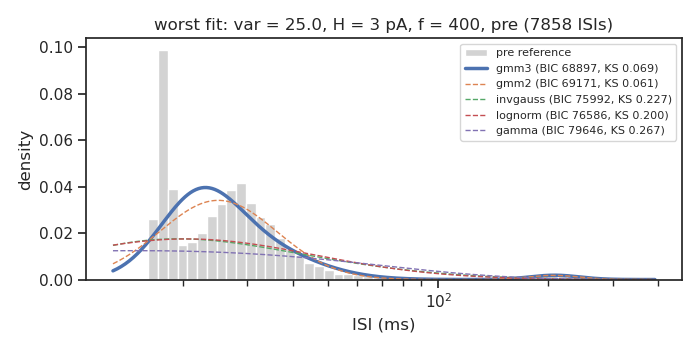

In [2]:
Image("summary_plots/failed_convergence.png")

##### Example of a good parametric fit to the data.

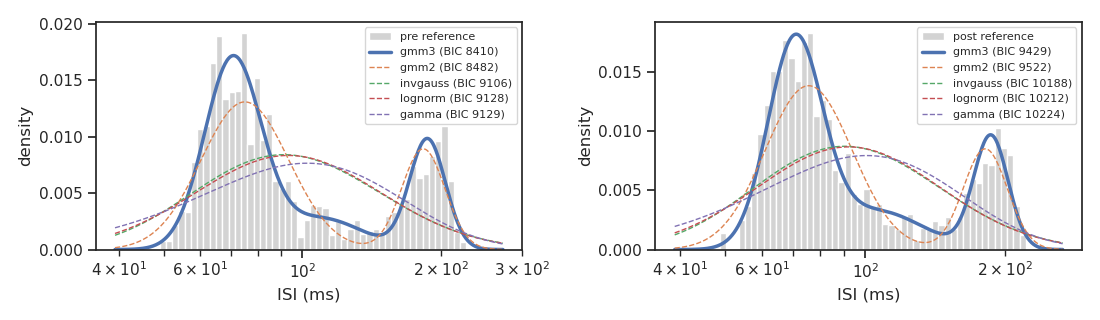

In [3]:
Image("summary_plots/good_convergence.png")

### Methods

The below image demonstrates the process of changepoint detection using the AQUA model. 

(1) A gaussian white noise current (50Hz sample rate) is injected containing a change point 5 sec into the simulation. This change point could be a change in the mean of the injected current, or a change in the variance.

(2) Each neuron was simulated under different seeds of the noisy current producing a membrane trace and spiking activity.

(3) This was repeated 100s of times to produce a population of spiking patterns pre- and post- change point.

(4) the pooled ISI distributions over all repeats demonstrate how spiking changes due to the changepoint. The divergence of the pre- and post-change point ISI distributions determines the theoretical best detection performance.

The process shown below is for the RS integrator neuron with no autapse. We re-ran this process for different values of the peak autapse current ranging from f = 0-400pA representing the range of autapse currents observed experimentally in pyramidal neurons. Likewise, e = 0.2 ms^-1 and tau = 2 ms.

The injected currents were defined by different step heights (dH) and different noise levels (var). 

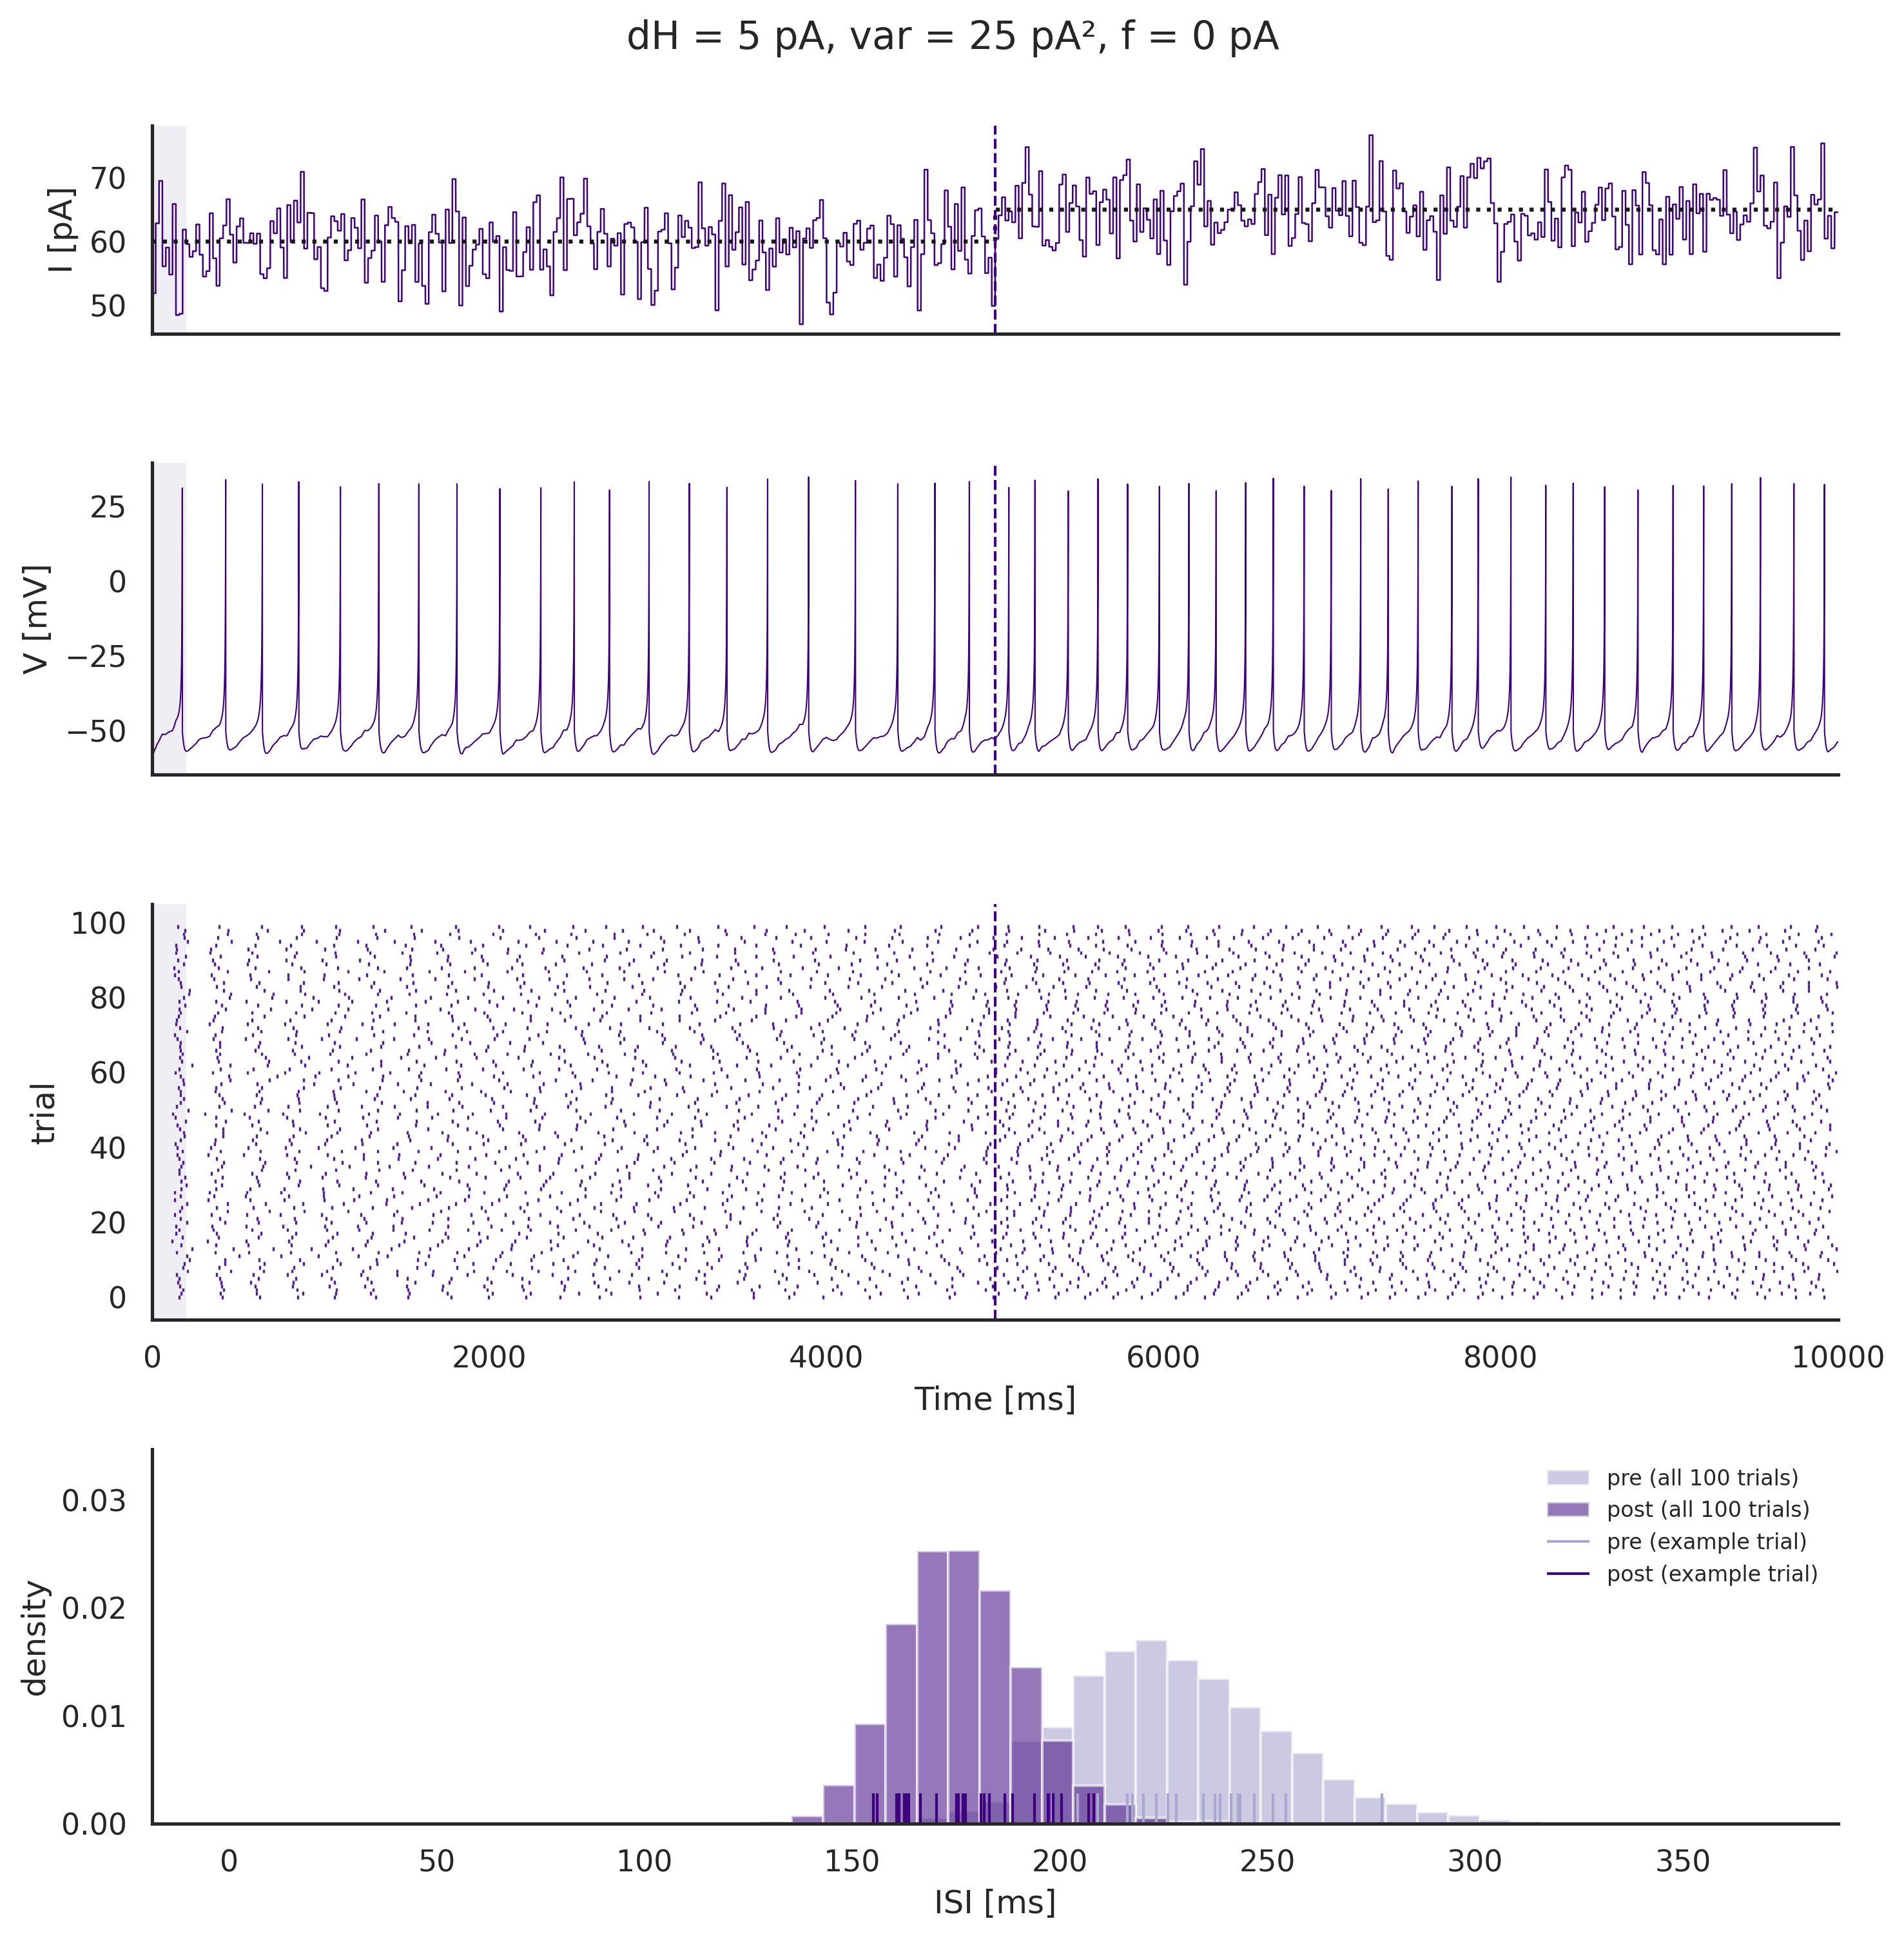

In [4]:
Image("summary_plots/N100_example_var25_dH5_f0_current_voltage_raster_ISI.png")

#### Divergence

A key factor determining the 'detectability' of the change point is the divergence between the pre- and post- change point ISI distributions. Non-parametric measures of divergence are the Kolmogorov-Smirnov distance and the energy distance. 

For each step height and noise level and autapse current, there is a measure of divergence between the ISI distributions. This plot of divergence vs step height for each autapse and noise level can be summarised into a single value as the **area under the divergence curve**. This is a summary metric representing the distinguishability of the pre- and post-ISI distributions averaged over all step heights.

These **AUC** curves are shown below for different measures of divergence on the ISI distributions. We can see that divergence scores, when considering single neurons, degrades with increasing autapse strength (f). When energy distance is calculated on a log-scale, there is a clear rise in divergence up to f~200pA and then a sharp decline as f increases. When ISIs are considered in units of ms, the rise in divergence is less clear. This suggests that the _relative_ distance between the pre- and post-distributions are enhanced in the autaptic condition up to a point.

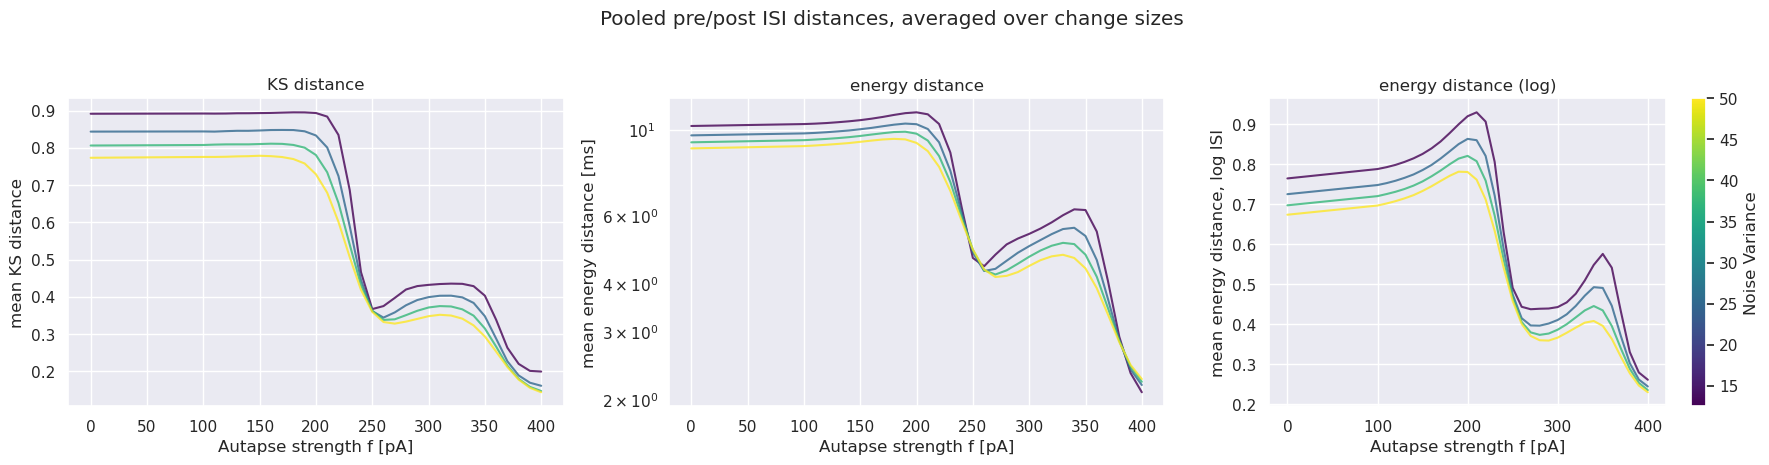

In [5]:
Image("summary_plots/N250_mean_ISI_empirical_distance_AUC_vs_f.png")

To understand why divergence decreases after some cutoff, it is helpful to see the underlying ISI distribuitons for representative conditions (see below). 

Each ro wbelow corresponds to a different f condition, each column represents a different step height. We can see that for f > 220pA, the neuron begins to burst at which point the bursting-ISI (left in each plot) is mostly fixed by the internal dynamics of the neuron and is largely insensitive to external currents. This peak is undifferentiated between the pre- and post- changepoint conditions so the divergence is mostly due to difference in the smaller tonic-firing ISI peak (right in each plot).

Shown in each plot is a gaussian mxture model fit to the logISI data. For the most part these fits work well and an analysis of each gaussian component is discussed below. 


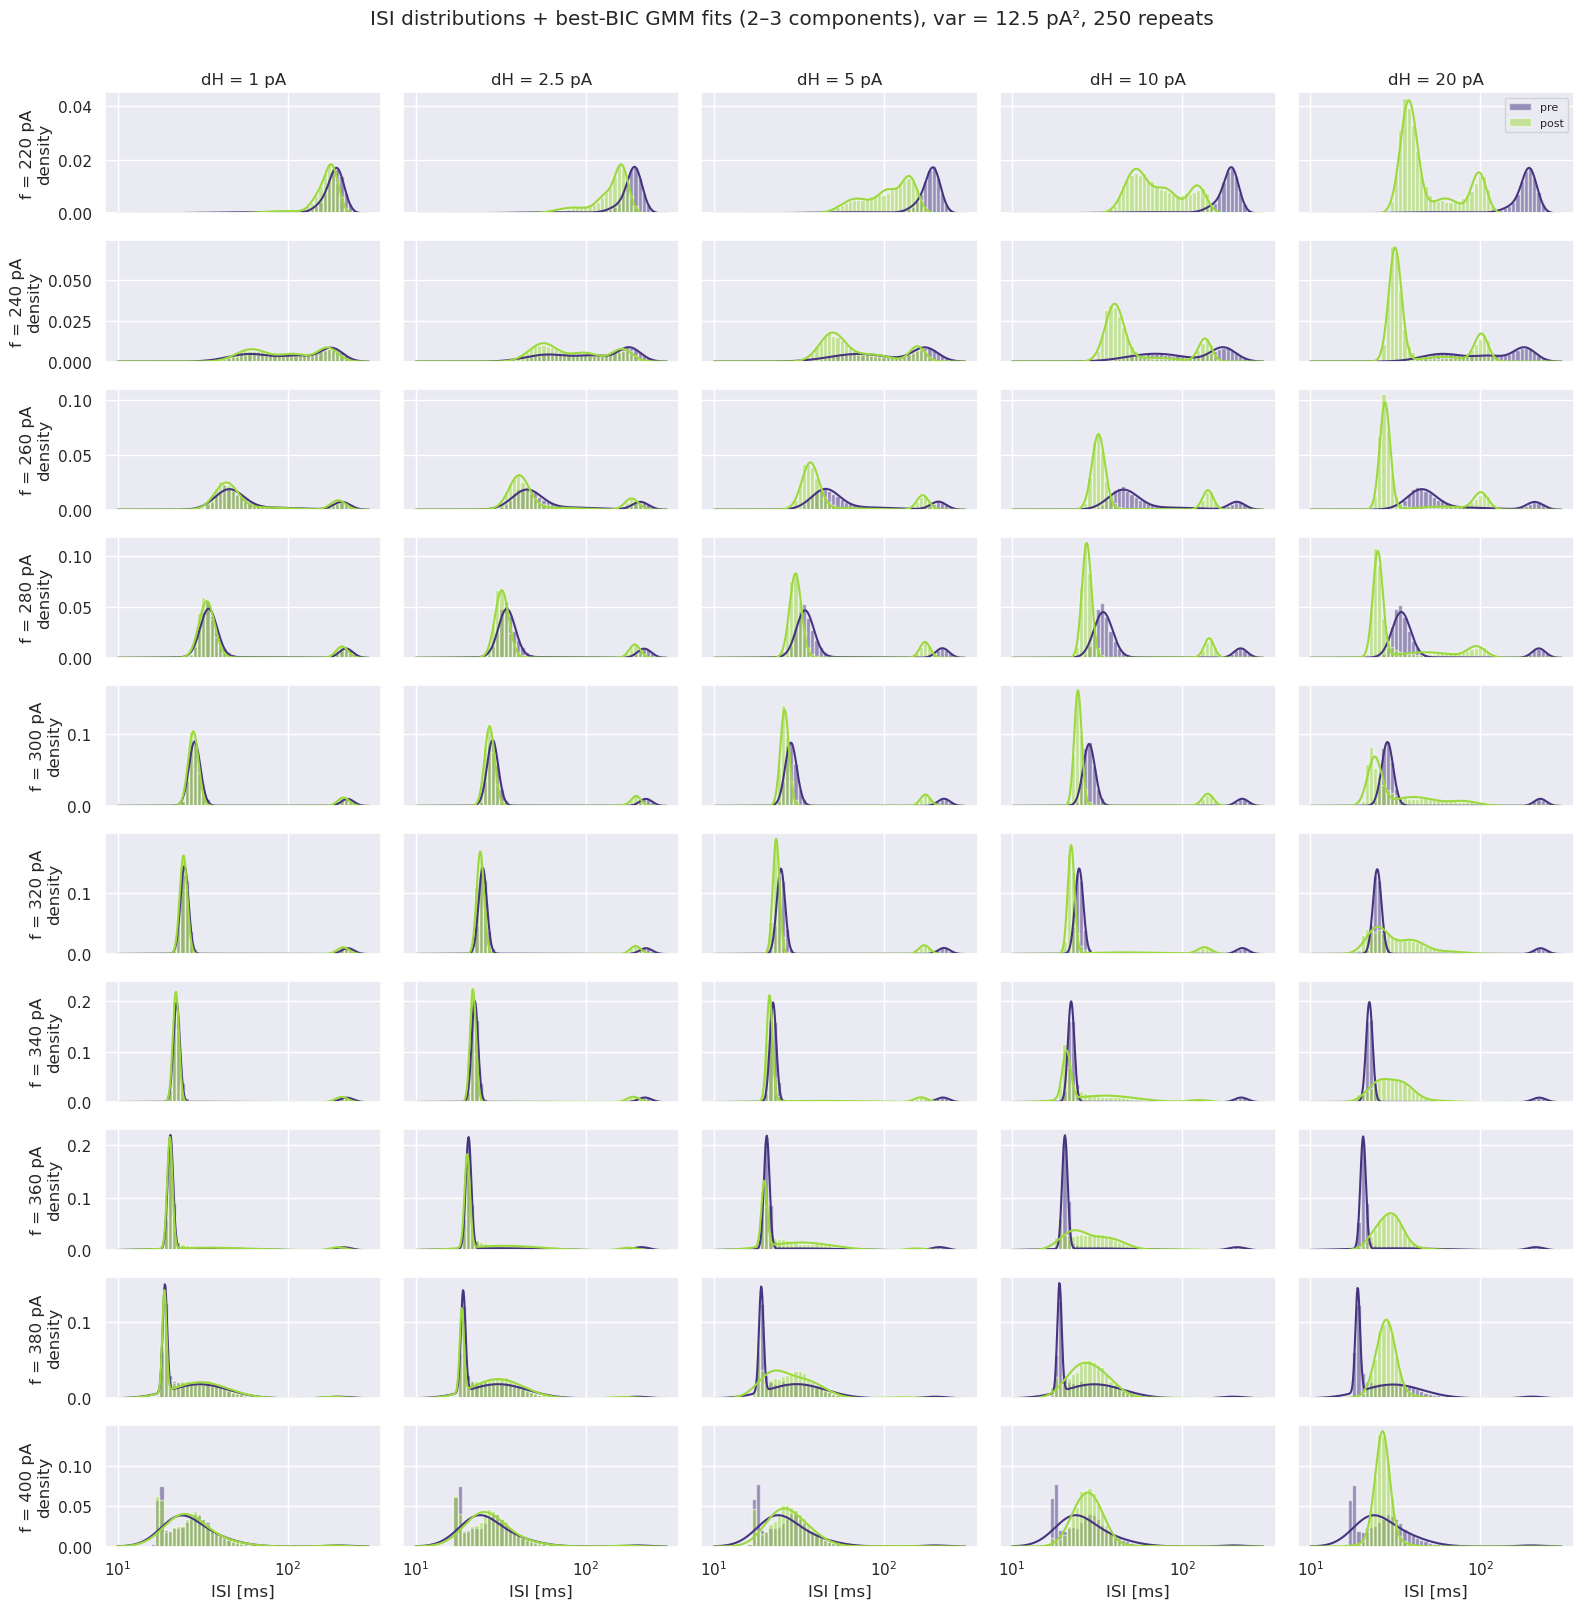

In [6]:
Image("plots/N250_mean_isi_gmm_grid.png")

Fitting a GMM to the logISI distributions reveals that three peaks fit the data best. There is a short ISI component corresponding to burst-ISIs (top row). A middle component corresponding to noisy interburst spikes (middle row), and a long-ISI component corresponding to interburst intervals (bottom row). Each component is described by a mean (1st column), s.d. (2nd column), and a weight (3rd column, all weights sum to 1).  

The 3rd column is most revealing of what is happening in the region of f=240-350 pA where performance seems to degrade. 
(1) the bursting component grows to represent ~50% of spikes. 
(2) the noisy component falls to near 0
(3) the tonic firing component decreases to about 50%

Clearly in this region, the autapse turns the neuron into a near perfect burster in which noise has little effect in disrupting this pattern. Indeed, it is only at higher f values (~300-375) and higher step changes (dH = 5, 10, 20pA) that this trend starts breaking down and the middle component begins to grow again. 

I propose that the smaller divergence in this regime is due to the fact that the bursti-ISI peak is determined by internal dynamics and won't be differentiated in the pre- and post- changepoint conditions. After the neuron bursts, there adaptation current is large, resulting in a large AHP making the neuron more robust to noise. This means that the interburst ISI peak doesn't diverge too much either leading to a small overall divergence value. 

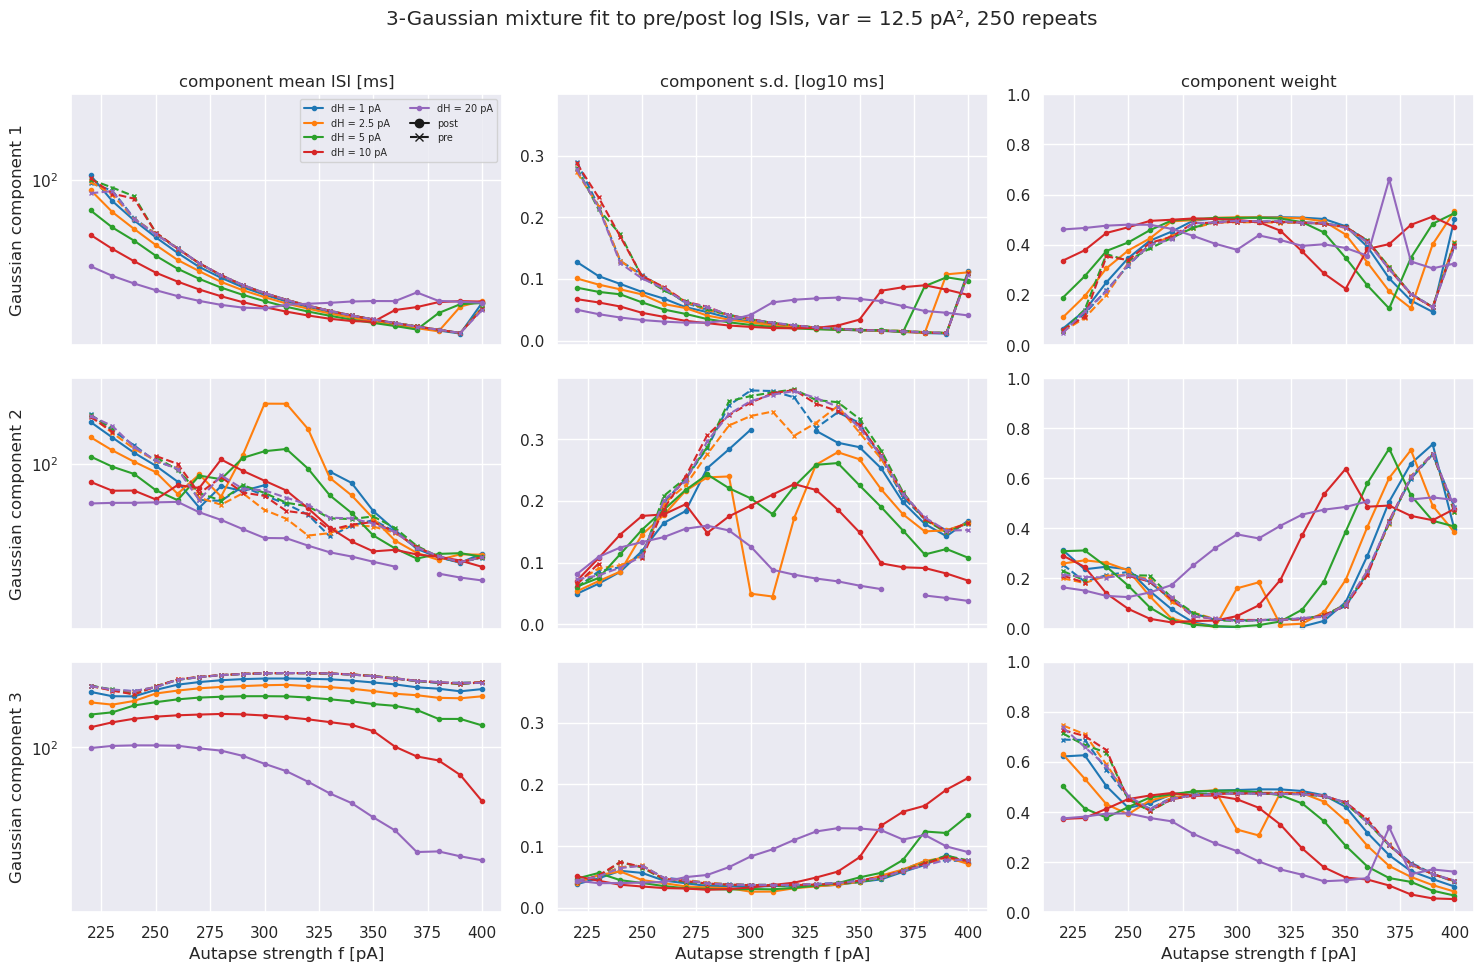

In [7]:
Image("plots/N250_mean_isi_gmm_params.png")

These divergence trends are reflected by the accuracy of the change time estimate. Regardless of the choice of how to quantify the 'error' between a change point time versus the actual, performance degrades with increasing autapse strength.

(1) Top Plot: mean error of the change point time versus step height for different noise levels. Differences aren't major, but typically stronger autapses produce larger errors.

(2) Bottom Plot: The smallest step height that can be reliably detected by each neuron. Each row represents a different thresold error between the estimated and actual change point times. Left column plots the minimum step height for different noise levels, Right plot shows the mean step heigh over all noise levels. 

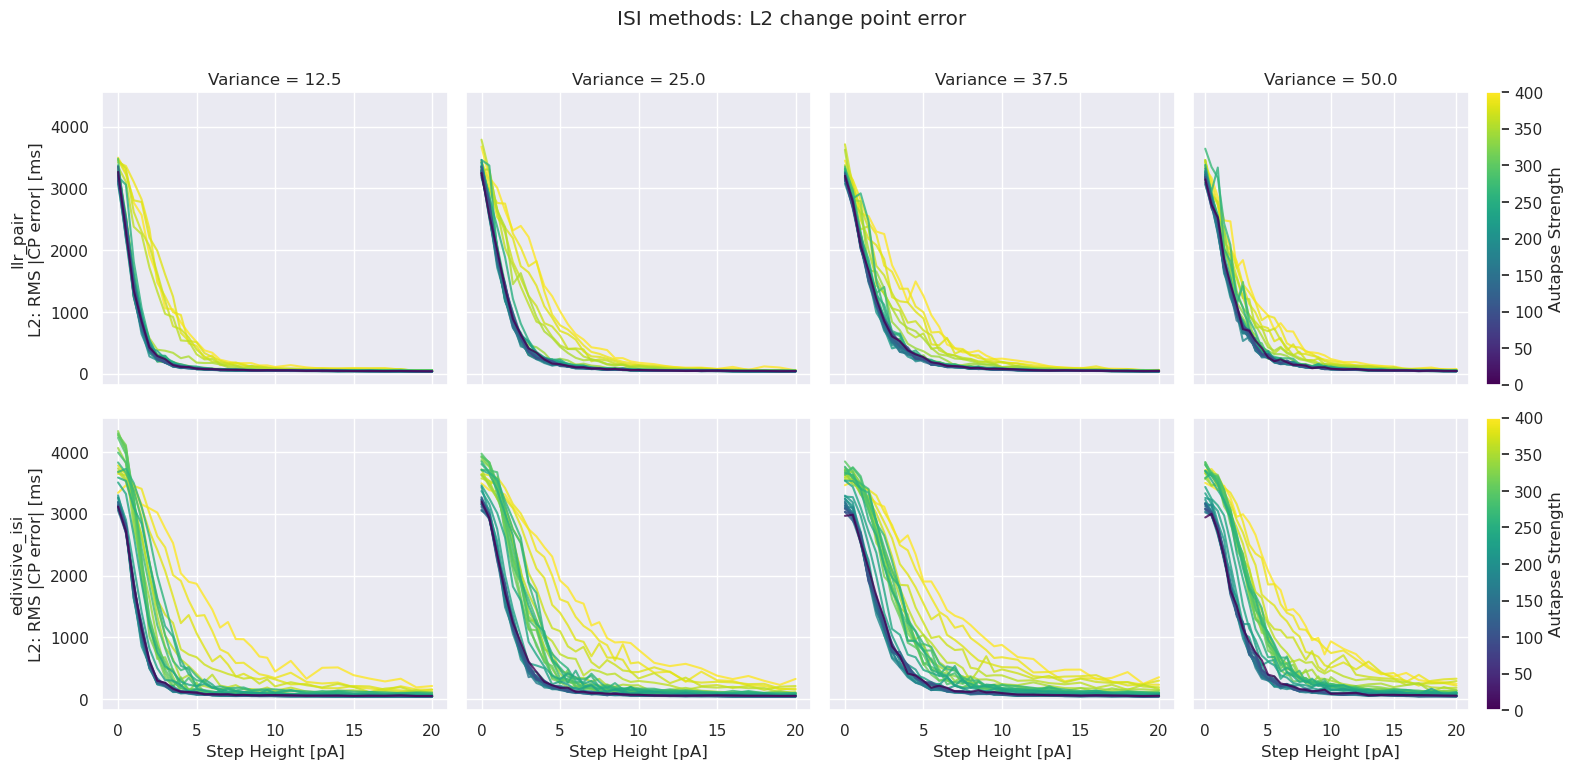

In [8]:
Image("summary_plots/N250_mean_ISI_methods_L2.png")

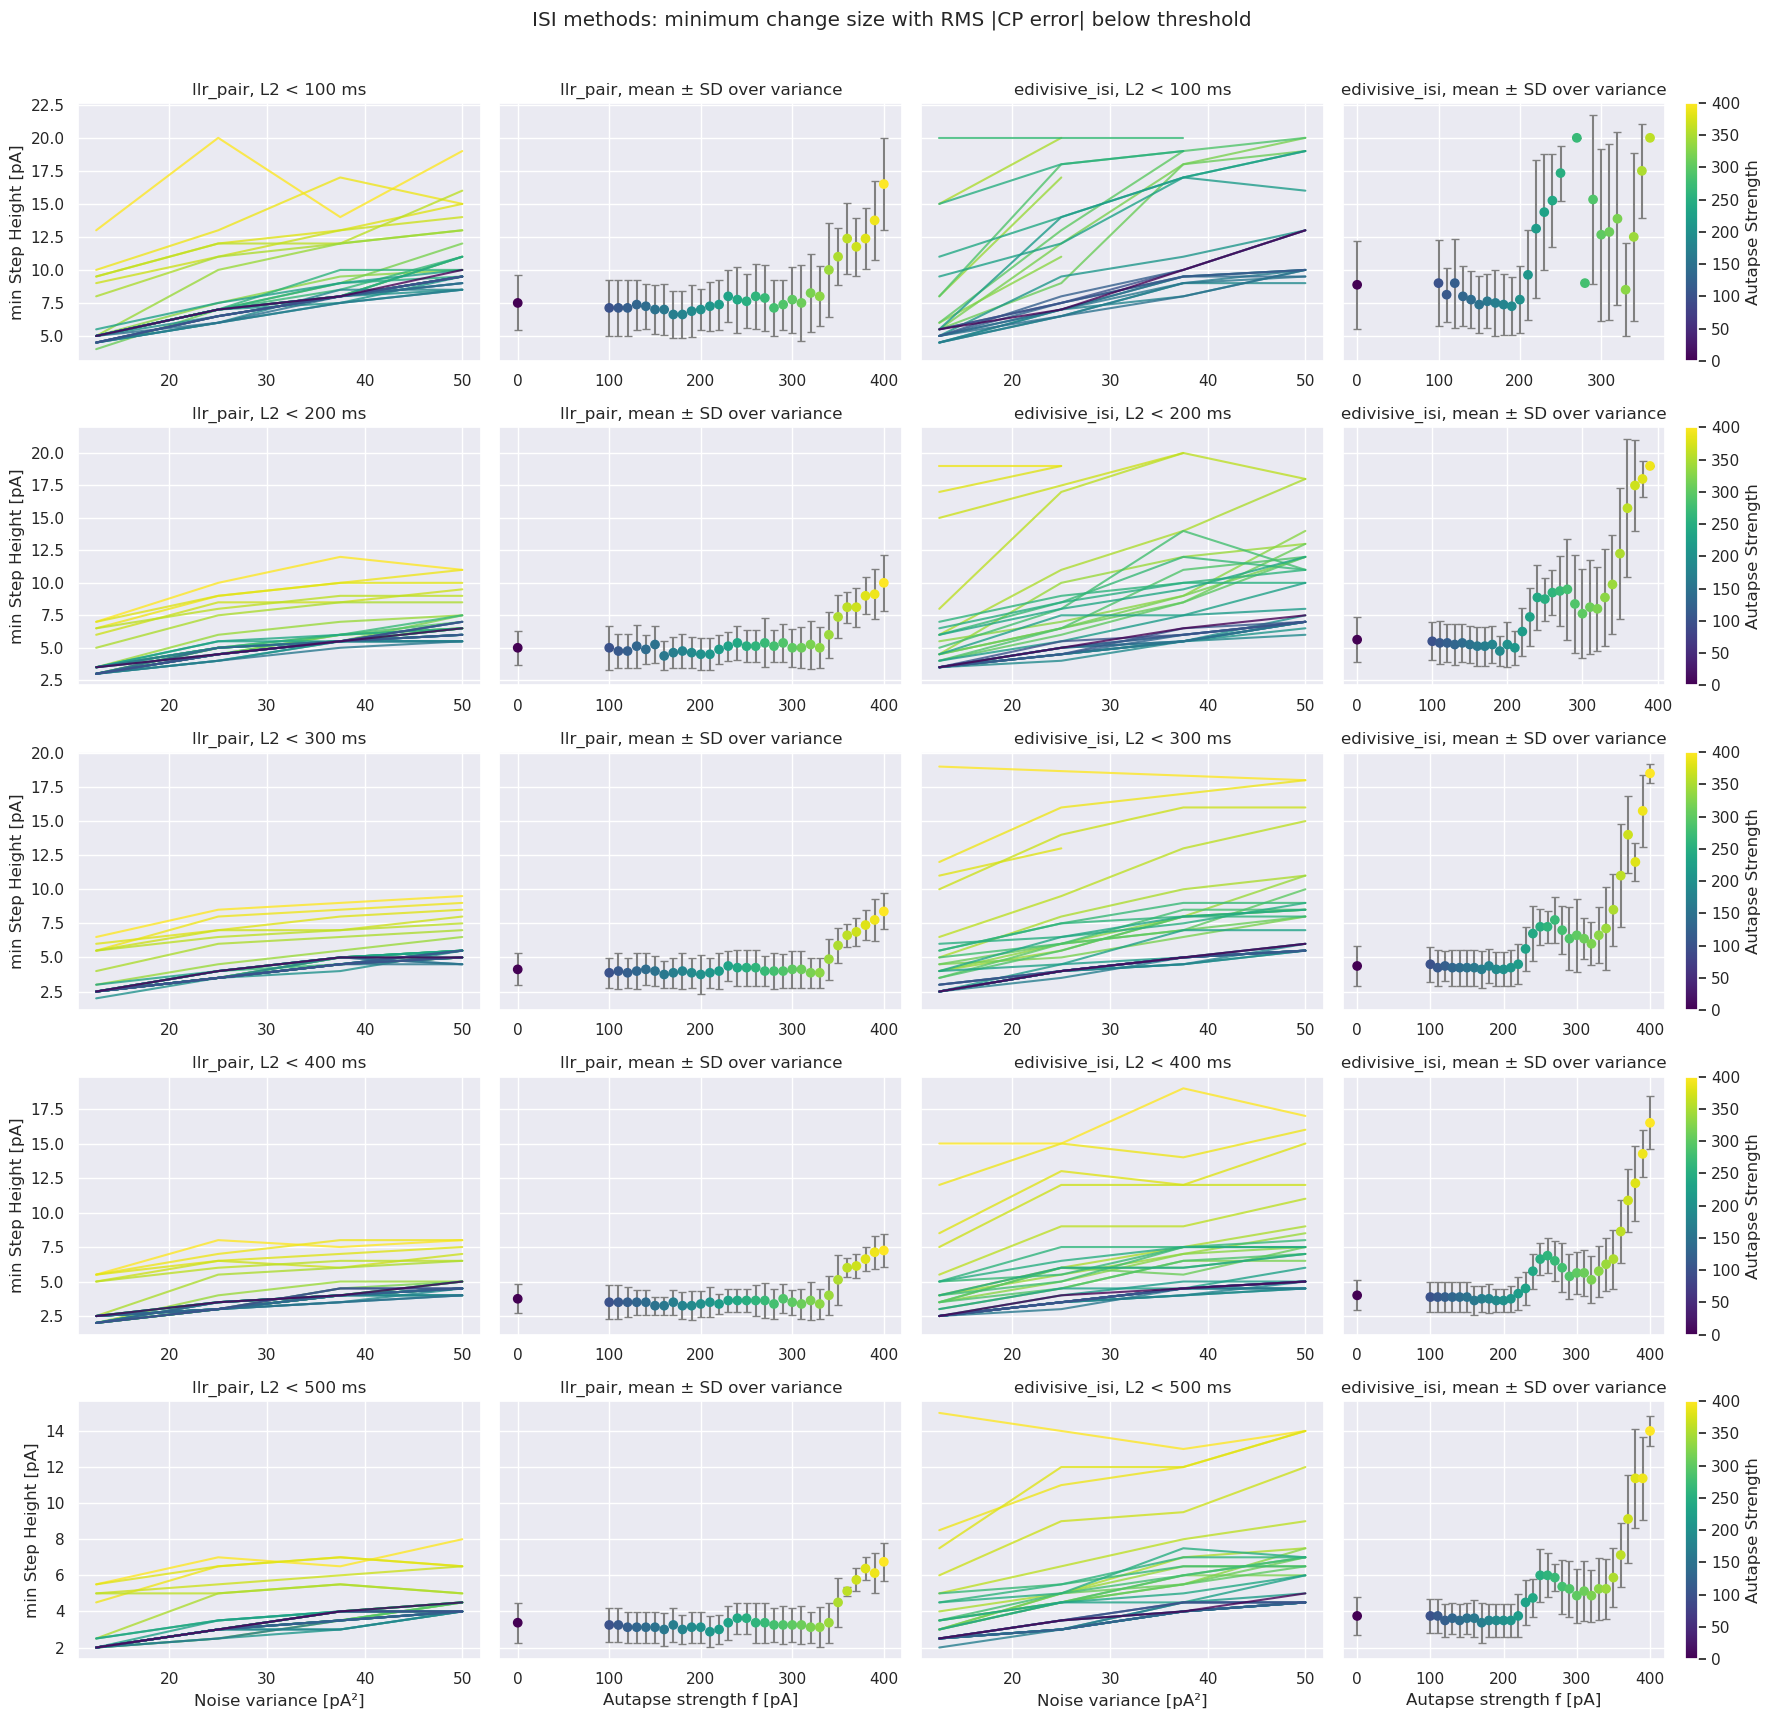

In [9]:
Image("summary_plots/N250_mean_ISI_methods_min_step_L2.png")

### Population level simulations

Change point detection algorithms aren't designed for spiking data. Rather they are designed to function on mostly continuous signals. As neurons function in concert in the brain, we then investigate the change point detectability when all neuron responses are pooled into a single psth. In this analysis, all neurons are uncoupled but receive a noisy version of the same change point signal. Signals are reflective of the firing rate of the neuron population in a 50ms time window, rather than the particular spike pattern. 

The figure below demonstrates example data for a representative run. Initial inspection suggests that this time, the autapse increases the discriminability of the input signal. 

The change point algorithms used in this analysis are sst, esst, and edivisive.


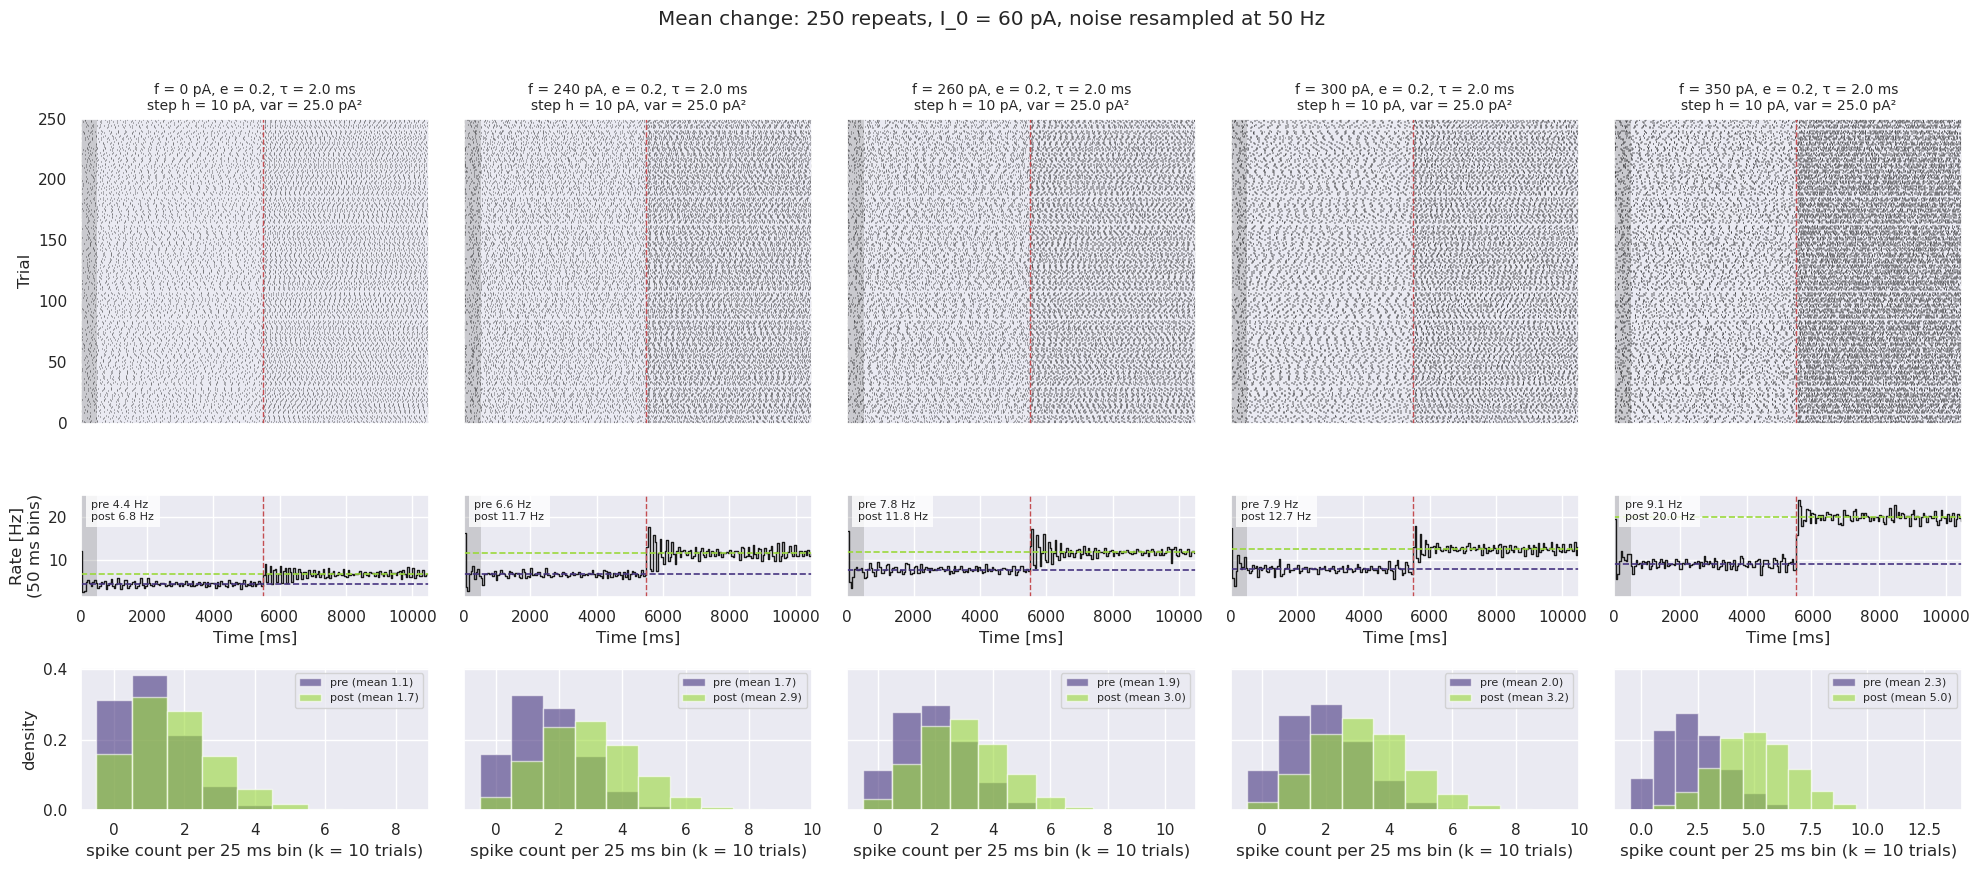

In [10]:
Image('summary_plots/N250_mean_PSTH_raster_example.png')

In this case, divergence and Change point error metrics show much more favourable results for autapses. Althought there is still a relative drop in performance around f~220-320pA in which divergences decay slightly. 

In general, here the increasing autapse strength improves change point detection as the high-f changepoint error curves decay fastest.

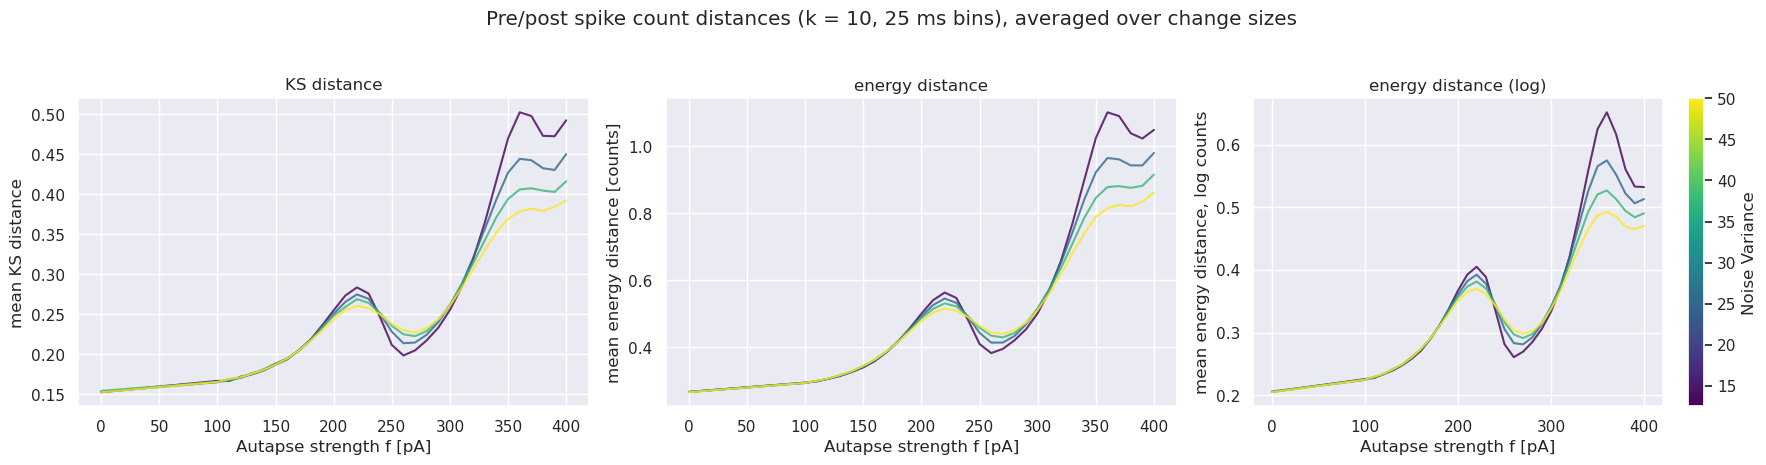

In [11]:
Image('summary_plots/N250_mean_PSTH_empirical_distance_vs_f.png')

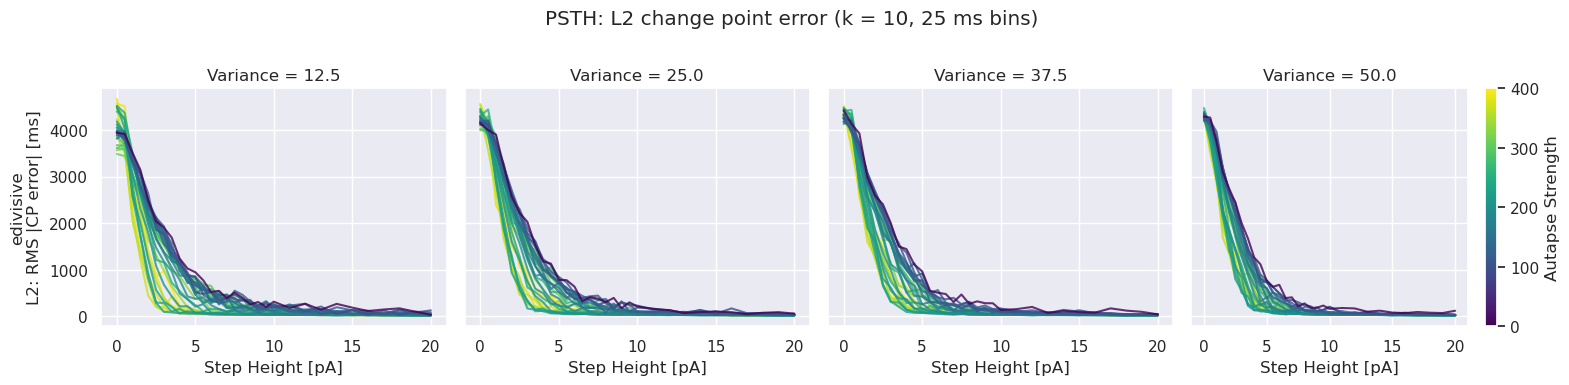

In [12]:
Image('summary_plots/N250_mean_PSTH_L2.png')

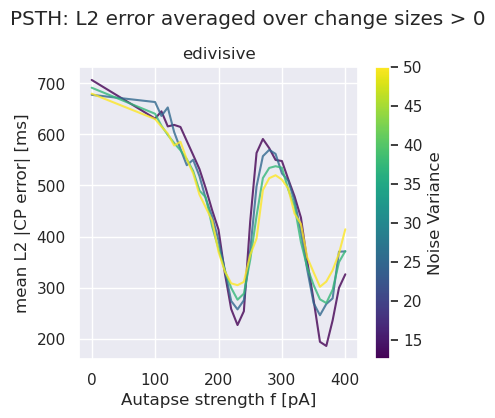

In [13]:
Image('summary_plots/N250_mean_PSTH_L2_vs_f.png')

Correspondingly, the minimal step height that is differentiable by the neuron, is dependent on the autapse strength. The autapse generally decreases the step height required for change point detection.

There are two interesting phenomena that appear in this and the above plots:

(1) There is a moderate value of the autapse strength in which the change point detection starts degrading (f ~ 250-350pA)

(2) It appears that the minimal detectable step height _decreases_ with increasing noise levels.

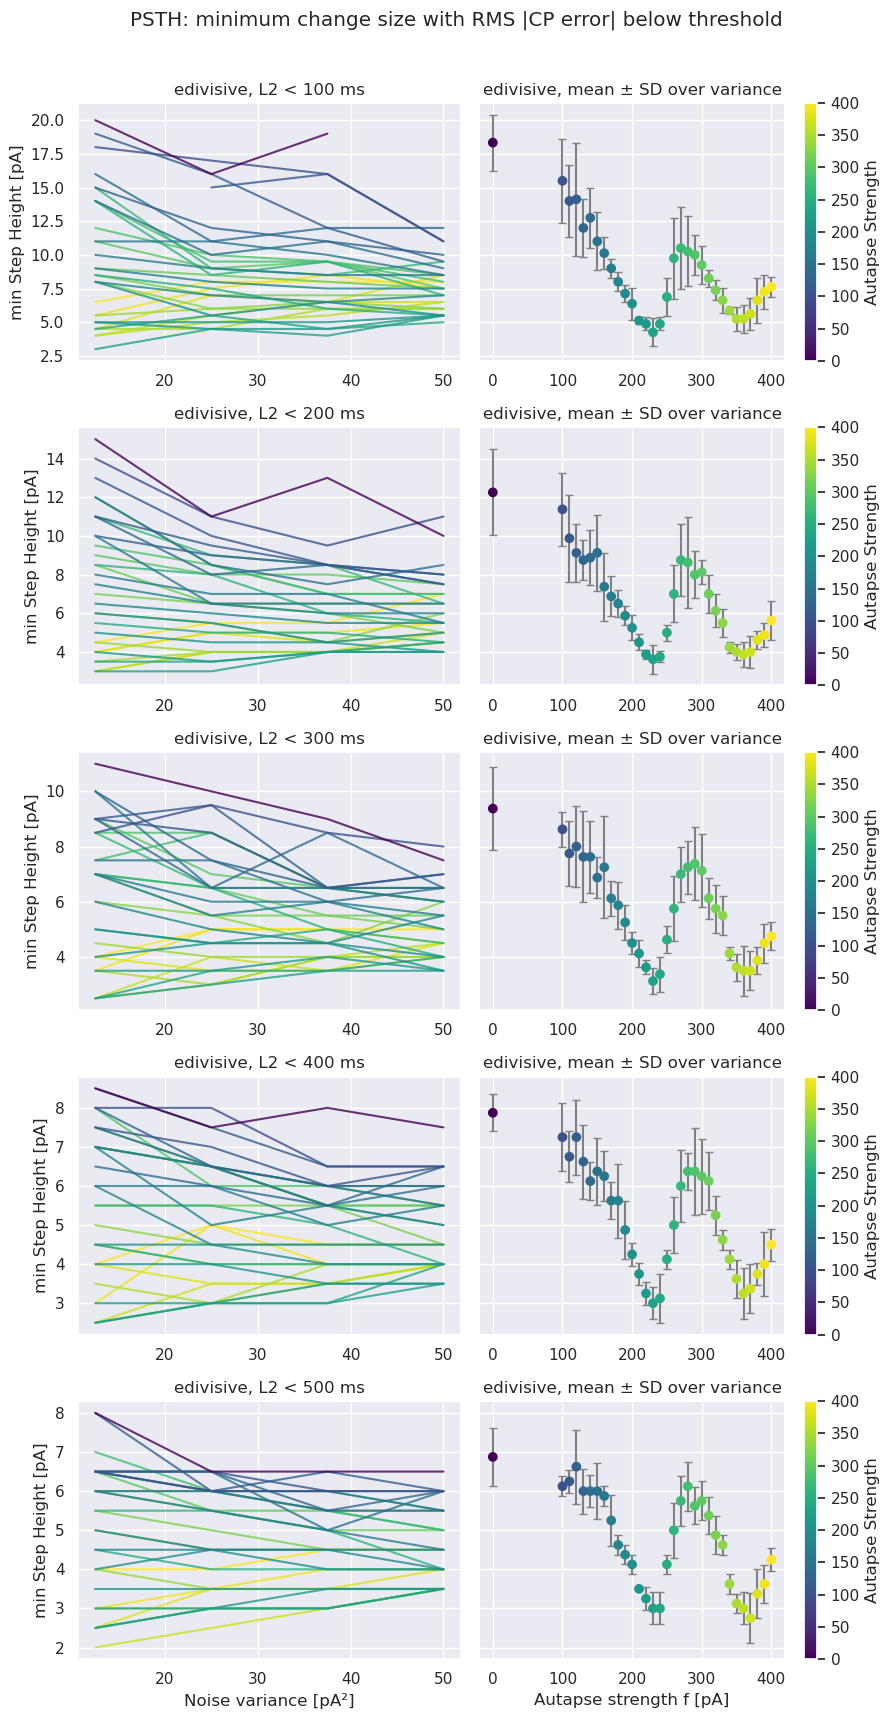

In [14]:
Image('summary_plots/N250_mean_PSTH_min_step_L2.png')

These two features may be explained, I believe, by the argument made for the ISI distributions above: in the low f case, the neuron is in a tonic _firing_ regime, while in the f~240-350pA case, the neuron is in a tonic _bursting_ regime. These regimes are effectively very similar, resulting in similar change point detection performance in each case. It is in the transition into (f < 220 pA) and out of (f> 350 pA) the bursting regime, that the neuron allows for a better detection performance.  

The plots below support this fact via the difference in pre- and post- firing rates and the signal to noise ratio. 

At intermediate autapse strengths of f~230-350pA, the signal to noise ratio of the psth signal drops drastically to those of the low-autapse condition (this is also reflected in the results above on the minimal step height and the error values). 

The reason for the increased signal-to-noise ratio in this parameter range is because the neuron starts bursting in this region. As such even the psth signal becomes bimodal, inflating the standard deviation. The signal-to-noise ratio artifically decreases as a result, but this nonetheless affects the change point detection performance. 

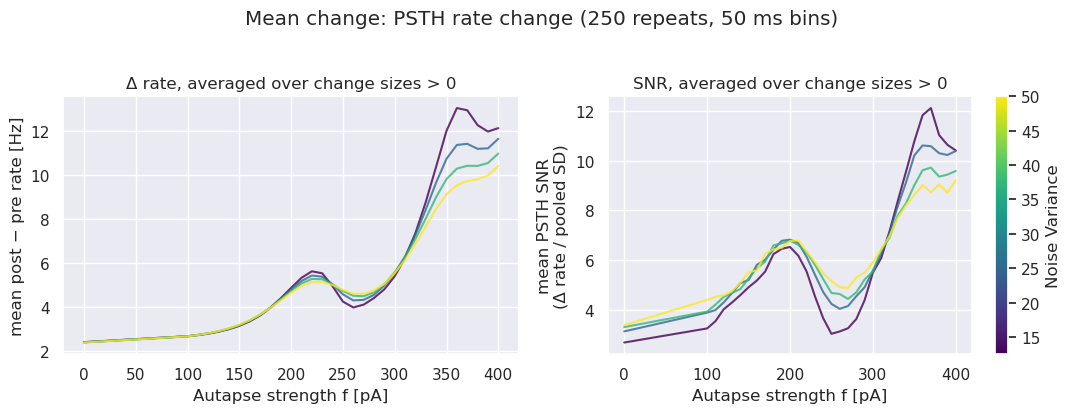

In [15]:
Image('summary_plots/N250_mean_PSTH_rate_change_vs_f.png')

### Conclusions

We've uncovered an interesting phenomenon in which the autapse does in fact improve the changepoint detection abilities of the neuron. This effect isn't trivial however as the performance is almost best _just before_ the transition to bursting. This value of f~220 pA for the monoexponential autapse corresponds to a peak biexponential autapse current of f = 147 pA when using biologically measured parameters. *This value is equal to the mean peak autapse current measured by Yin _et al._ 2018*. Experimentally, the peak current has been measured as high as 450 pA, corresponding to f ~ 680 pA in the monoexponential case. 

The subsequent section to this one in the paper investigates the synchronisation abilities of the neuron in a microcircuit. In this case, the bursting regime is the optimal regime for this. We would then have a use case for neurons for all experimentally measured autapse values.  

In [16]:
!jupyter nbconvert --to html CPA_summary.ipynb

[NbConvertApp] Converting notebook CPA_summary.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 14 image(s).
[NbConvertApp] Writing 4755452 bytes to CPA_summary.html
